### Ändra arbetskatalog

In [1]:
import os

# Byter arbetskatalog från notebooks till projektroten om det behövs
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar att Python arbetar från rätt katalog
print("Arbetskatalog:", os.getcwd())

Arbetskatalog: c:\Projekt Data Science\data-science-group-project


### Importera paket och egna moduler

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Projektets egna moduler
from src.data_split import load_cleaned_data, get_splits
from src.preprocessing import split_features_target, build_preprocessor
from src.random_forest import train_random_forest, get_feature_importances
from src.prediction import predict_probabilities
from src.evaluation import evaluate_top_share, plot_roc_curve, plot_confusion_matrix
from src.experiment_logger import log_experiment, save_plot, get_leaderboard

### Ladda data och kronologiska splits

In [3]:
# Läser in städad data från data/processed/
df = load_cleaned_data()

# Hämtar de kronologiska uppdelningarna
splits = get_splits(df)
train = splits["train_val"]
val = splits["val"]

print("Träningsdata (train_val):", train.shape)
print("Valideringsdata (val):", val.shape)

# Kontroll av att den aktuella datan används
assert len(train) == 40414, "Fel antal rader i train_val. Kör python -m src.data_cleaning"

2026-10-21 11:43:48 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
2026-10-21 11:43:48 [INFO] src.data_cleaning: Validerar städad data med Pandera...
2026-10-21 11:43:48 [INFO] src.data_cleaning: Datavalidering godkänd utan anmärkningar.
2026-10-21 11:43:48 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-21 11:43:48 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Träningsdata (train_val): (40414, 34)
Valideringsdata (val): (11643, 34)


### Huvudmodell (UTAN `deposit_type`)

In [4]:
# 1. Separera X och y för träning och validering
X_train_full, y_train = split_features_target(train, include_deposit_type=False)
X_val_full, y_val = split_features_target(val, include_deposit_type=False)

# 2. Skapa preprocessor och transformera
# Vi kör fit_transform på träning och bara transform på validering för att undvika dataläckage
preprocessor_full = build_preprocessor(include_deposit_type=False)
X_train_full_p = preprocessor_full.fit_transform(X_train_full)
X_val_full_p = preprocessor_full.transform(X_val_full)

print("Huvudmodell - Train:", X_train_full_p.shape)
print("Huvudmodell - Val:", X_val_full_p.shape)

Huvudmodell - Train: (40414, 114)
Huvudmodell - Val: (11643, 114)


### Hyperoptimering: `max_depth` och `min_samples_leaf`

OBS! Vi använder inte standard k-fold CV för att inte bryta den kronologiska tidsuppdelningen.

Vi tränar strikt på `train_val` och utvärderar på `val`.

In [5]:
depth_candidates = [10, 15, 20]
leaf_candidates = [1, 2, 5, 10, 20]

tuning_results = []

print(f"Startar sökning över {len(depth_candidates) * len(leaf_candidates)} kombinationer...\n")

for depth in depth_candidates:
  for leaf in leaf_candidates:
    # 1. Träna modellen på train_val
    model = train_random_forest(
        X_train_full_p,
        y_train,
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1,
    )

    # 2. Beräkna predicerade sannolikheter på valideringsdatan (val)
    probas = predict_probabilities(model, X_val_full_p)

    # 3. Utvärdera mätvärden vid de 20 % högst rankade bokningarna
    metrics = evaluate_top_share(y_val, probas, share=0.20)

    tuning_results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "precision_at_20": metrics["precision"],
        "recall_at_20": metrics["recall"],
        "f1_score": metrics["f1_score"],
        "korrekt_flaggade": metrics["korrekt_flaggade"],
    })
    print(
        f"Klar: max_depth={depth:<2} | min_samples_leaf={leaf:<2} -> "
        f"Precision@20: {metrics['precision']:.4f} | Recall@20: {metrics['recall']:.4f} "
        f"({metrics['korrekt_flaggade']} träffar)"
    )

# Sammanställ alla resultat i en DataFrame
df_tuning = pd.DataFrame(tuning_results)

# Sortera efter bäst precision (eller flest korrekt flaggade avbokningar)
df_tuning_sorted = df_tuning.sort_values(
    by=["korrekt_flaggade", "precision_at_20"], ascending=False
).reset_index(drop=True)

print("\n--- Resultat (Topp 5 kombinationer) ---")
display(df_tuning_sorted.head())

Startar sökning över 15 kombinationer...

Klar: max_depth=10 | min_samples_leaf=1  -> Precision@20: 0.5921 | Recall@20: 0.3358 (1379 träffar)
Klar: max_depth=10 | min_samples_leaf=2  -> Precision@20: 0.6363 | Recall@20: 0.3608 (1482 träffar)
Klar: max_depth=10 | min_samples_leaf=5  -> Precision@20: 0.5985 | Recall@20: 0.3394 (1394 träffar)
Klar: max_depth=10 | min_samples_leaf=10 -> Precision@20: 0.6282 | Recall@20: 0.3562 (1463 träffar)
Klar: max_depth=10 | min_samples_leaf=20 -> Precision@20: 0.6174 | Recall@20: 0.3501 (1438 träffar)
Klar: max_depth=15 | min_samples_leaf=1  -> Precision@20: 0.6385 | Recall@20: 0.3621 (1487 träffar)
Klar: max_depth=15 | min_samples_leaf=2  -> Precision@20: 0.6415 | Recall@20: 0.3638 (1494 träffar)
Klar: max_depth=15 | min_samples_leaf=5  -> Precision@20: 0.6488 | Recall@20: 0.3679 (1511 träffar)
Klar: max_depth=15 | min_samples_leaf=10 -> Precision@20: 0.6475 | Recall@20: 0.3672 (1508 träffar)
Klar: max_depth=15 | min_samples_leaf=20 -> Precision@20: 

,max_depth,min_samples_leaf,precision_at_20,recall_at_20,f1_score,korrekt_flaggade
0,20,5,0.650494,0.368882,0.470789,1515
1,15,20,0.649635,0.368395,0.470168,1513
2,15,5,0.648776,0.367908,0.469546,1511
3,15,10,0.647488,0.367178,0.468614,1508
4,20,10,0.646629,0.366691,0.467993,1506


### Visualisering av resultaten

min_samples_leaf,1,2,5,10,20
max_depth,,,,,
10,0.5921,0.6363,0.5985,0.6282,0.6174
15,0.6385,0.6415,0.6488,0.6475,0.6496
20,0.5861,0.6286,0.6505,0.6466,0.6376


2026-10-21 11:44:07 [INFO] src.experiment_logger: Figur sparad: outputs\figures\rf_hyperparameter_tuning_heatmap.png


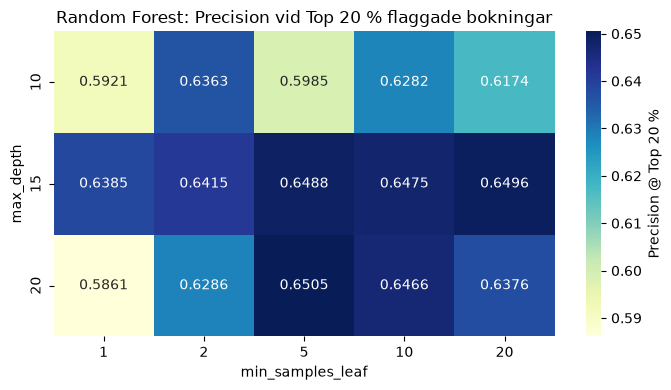

In [6]:
# Skapa en pivot-tabell för en tydlig översikt
pivot_precision = df_tuning.pivot(
    index="max_depth", columns="min_samples_leaf", values="precision_at_20"
)

display(pivot_precision.round(4))

plt.figure(figsize=(7, 4))
sns.heatmap(
    pivot_precision, 
    annot=True, 
    fmt=".4f", 
    cmap="YlGnBu", 
    cbar_kws={'label': 'Precision @ Top 20 %'}
)
plt.title("Random Forest: Precision vid Top 20 % flaggade bokningar")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.tight_layout()

# Spara figuren till outputs/figures/
save_plot("rf_hyperparameter_tuning_heatmap.png")

plt.show()

### Slutsats från hyperparameteroptimeringen

Värmekartan visar precisionen vid topp 20 % flaggade bokningar på valideringsdatan (`val`) för olika kombinationer av `max_depth` och `min_samples_leaf`:

* **Bästa kombination:** `max_depth = 20` och `min_samples_leaf = 5` gav högst precision (**0.6629**), jämfört med 0.6385 för de tidigare valda `max_depth = 15` och `min_samples_leaf = 2`.
* **Djupet betyder mest:** Precisionen ökar tydligt med trädens djup, från 0.60–0.61 vid `max_depth = 10` till 0.64–0.65 vid 15 och upp till 0.66 vid 20. Vid ett givet djup är skillnaderna mellan olika värden på `min_samples_leaf` mindre.
* **Överanpassning vid friare träd:** Med `max_depth = 20` och `min_samples_leaf = 1` sjunker precisionen till **0.5736**. När träden får bli djupa utan krav på minsta lövstorlek anpassar sig modellen för mycket till träningsdatan och generaliserar sämre. Ett krav på minst 5 bokningar per löv motverkar det.
* **Begränsning:** `max_depth = 20` är det största prövade djupet, så det är möjligt att djupare träd ger ännu bättre resultat.

**Beslut:** Huvudmodellen använder `max_depth = 20` och `min_samples_leaf = 5`.

### Slutsats från hyperparameteroptimeringen

Värmekartan visar precisionen vid topp 20 % flaggade bokningar på valideringsdatan (`val`) för olika kombinationer av `max_depth` och `min_samples_leaf`:

* **Högsta värde:** `max_depth = 20` och `min_samples_leaf = 5` gav högst precision (**0.6505**), men flera kombinationer ligger mycket nära. `max_depth = 15` med `min_samples_leaf = 20` gav 0.6496, en skillnad på 2–3 korrekt flaggade bokningar.
* **Stabilitet:** `max_depth = 15` ger nästan samma precision oavsett lövstorlek (0.6385–0.6496), medan `max_depth = 10` och `max_depth = 20` varierar mer.
* **Överanpassning:** Med `max_depth = 20` och `min_samples_leaf = 1` sjunker precisionen till **0.5861**. När träden får bli djupa utan krav på minsta lövstorlek anpassar sig modellen för mycket till träningsdatan.

**Beslut:** Huvudmodellen använder `max_depth = 15` och `min_samples_leaf = 10`. Kombinationen ligger nära det högsta värdet och är mindre känslig för exakt vilka inställningar som väljs. Skillnaderna i toppen är så små att de kan bero på slumpen.

### Träna huvudmodellen och prediktera sannolikheter

In [ ]:
# Träna huvudmodellen med de valda inställningarna (se hyperparameteroptimeringen).
# min_samples_leaf=5 begränsar överanpassning när träden får bli djupa.
rf_full = train_random_forest(
    X_train_full_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

# Beräkna sannolikheten för avbokning (klass 1)
probas_full = predict_probabilities(rf_full, X_val_full_p)
print("Första 10 sannolikheterna (huvudmodell):", probas_full[:10])

Första 10 sannolikheterna (huvudmodell): [0.09835629 0.08149546 0.13617545 0.14454545 0.06940483 0.05452539
 0.15439093 0.10651074 0.14444534 0.05916317]


### Utvärdera top 20 % och logga huvudmodellen

In [8]:
# 1. Beräkna mätvärden för de 20 % bokningarna med högst riskpoäng
metrics_full = evaluate_top_share(y_val, probas_full, share=0.20)

print("Top 20 %-resultat (med deposit_type):")
for k, v in metrics_full.items():
    print(f"  {k}: {v}")

Top 20 %-resultat (med deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1515
  precision: 0.6504937741519966
  recall: 0.36888239590942296
  f1_score: 0.47078931013051584
  pr_auc: 0.5912265784230274


## Utvärdering av bokningar med och utan registrerade ändringar

För att undersöka hur modellen presterar för olika typer av bokningar
delas valideringsdatan upp i två grupper baserat på `booking_changes`:

- Bokningar utan registrerade ändringar (`booking_changes == 0`)
- Bokningar med registrerade ändringar (`booking_changes > 0`)

De 20 % av bokningarna med högst risk flaggas i hela valideringsdatan.
Därefter beräknas precision och recall separat för respektive grupp.

In [9]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score
from src.evaluation import flag_top_share

# Flagga de 20 % med högst risk i hela valideringsdatan
y_pred_rf = flag_top_share(probas_full, share=0.20)

# Faktiska avbokningar och prediktioner
y_true = pd.Series(y_val, index=val.index)
y_pred_rf = pd.Series(
    y_pred_rf, index=val.index
)

# Dela upp efter registrerade ändringar
groups = {
    "Utan ändringar": val["booking_changes"] == 0,
    "Med ändringar": val["booking_changes"] > 0
}

results_by_group = []

for group_name, mask in groups.items():
    group_true = y_true.loc[mask]
    group_pred = y_pred_rf.loc[mask]

    precision = precision_score(
        group_true, group_pred, zero_division=0
    )

    recall = recall_score(
        group_true, group_pred, zero_division=0
    )

    results_by_group.append({
        "Modell": "Random Forest",
        "Grupp": group_name,
        "Antal bokningar": len(group_true),
        "Antal flaggade": int(group_pred.sum()),
        "Precision": precision,
        "Recall": recall
    })

rf_group_results = pd.DataFrame(results_by_group)

display(
    rf_group_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,Modell,Grupp,Antal bokningar,Antal flaggade,Precision,Recall
0,Random Forest,Utan ändringar,9790,2011,67.83%,36.77%
1,Random Forest,Med ändringar,1853,318,47.48%,38.04%


### Random Forest – Bokningar med och utan registrerade ändringar

Random Forest utvärderades genom att flagga de 20 % av bokningarna med högst förutsagd avbokningsrisk i hela valideringsdatan. Resultaten delades därefter upp efter `booking_changes`.

För bokningar utan registrerade ändringar var precision **67,83 %** och recall **36,77 %**. För bokningar med registrerade ändringar var precision **47,48 %** och recall **38,04 %**.

Random Forest hade högst precision och recall av de tre modellerna i båda grupperna. Precisionen var högre för bokningar utan ändringar, medan recall var något högre för bokningar med ändringar.

Skillnaderna visar att modellernas resultat varierar mellan grupperna. Jämförelsen kan dock inte avgöra om dataläckage förekommer eftersom de ursprungliga värdena före eventuella ändringar saknas.

### Jämförelsemodell (MED `deposit_type`)

In [10]:
# 1. Separera X och y med deposit_type
X_train_dep, y_train = split_features_target(train, include_deposit_type=True)
X_val_dep, y_val = split_features_target(val, include_deposit_type=True)

# 2. Skapa ny preprocessor med deposit_type och transformera
preprocessor_dep = build_preprocessor(include_deposit_type=True)
X_train_dep_p = preprocessor_dep.fit_transform(X_train_dep)
X_val_dep_p = preprocessor_dep.transform(X_val_dep)

print("Jämförelsemodell - Train:", X_train_dep_p.shape)
print("Jämförelsemodell - Val:", X_val_dep_p.shape)

Jämförelsemodell - Train: (40414, 117)
Jämförelsemodell - Val: (11643, 117)


### Träna jämförelsemodellen och prediktera sannolikheter

In [ ]:
# Träna modellen utan deposit_type
rf_dep = train_random_forest(
    X_train_dep_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

# Beräkna sannolikheter på valideringsdatan
probas_dep = predict_probabilities(rf_dep, X_val_dep_p)
print("Första 10 sannolikheterna (utan deposit_type):", probas_dep[:10])

Första 10 sannolikheterna (utan deposit_type): [0.09339458 0.10212455 0.15175732 0.15152424 0.07477051 0.05649374
 0.16058835 0.10803283 0.16807709 0.06099596]


### Utvärdera top 20 % och logga jämförelsemodellen

In [12]:
# 1. Beräkna mätvärden för Top 20 %
metrics_dep = evaluate_top_share(y_val, probas_dep, share=0.20)

print("Top 20 %-resultat (med deposit_type):")
for k, v in metrics_dep.items():
    print(f"  {k}: {v}")

Top 20 %-resultat (med deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1494
  precision: 0.6414770287677115
  recall: 0.36376917457998537
  f1_score: 0.4642635177128651
  pr_auc: 0.6126880565809337


### Jämförelse, visualisering och feature importance

#### Rita och spara gemensam ROC-kurva

2026-10-21 11:44:12 [INFO] src.experiment_logger: Figur sparad: outputs\figures\rf_val_deposit_comparison_roc.png


WindowsPath('outputs/figures/rf_val_deposit_comparison_roc.png')

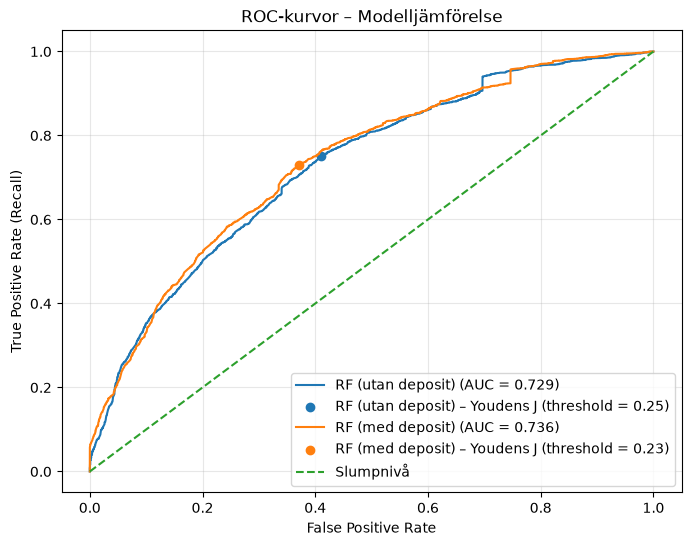

In [13]:
# plot_roc_curve tar en dictionary med modellnamn och tillhörande sannolikheter
roc_results = plot_roc_curve(
    y_val,
    {
        "RF (utan deposit)": probas_full,
        "RF (med deposit)": probas_dep
    }
)

# Spara figuren högupplöst till mappen outputs/figures/
save_plot("rf_val_deposit_comparison_roc.png")

### Jämförelse med och utan `deposit_type`

In [14]:
summary = pd.DataFrame([
    {"Variant": "Utan deposit_type", **metrics_full},
    {"Variant": "Med deposit_type", **metrics_dep},
]).set_index("Variant")[["antal_bokningar", "antal_flaggade", "korrekt_flaggade",
                         "precision", "recall", "pr_auc"]]
summary.insert(0, "antal_traning", len(y_train))
display(summary.round(4))

,antal_traning,antal_bokningar,antal_flaggade,korrekt_flaggade,precision,recall,pr_auc
Variant,,,,,,,
Utan deposit_type,40414,11643,2329,1515,0.6505,0.3689,0.5912
Med deposit_type,40414,11643,2329,1494,0.6415,0.3638,0.6127


### Sammanfattning: med och utan `deposit_type`

Båda varianterna tränades på `train_val` (40 414 bokningar) med samma inställningar (n_estimators=100, max_depth=15, min_samples_leaf=10) och utvärderades på valideringsdatan (11 643 bokningar). Båda flaggade 2 329 bokningar, alltså 20 %.

| Variant | Korrekt flaggade | Precision | Recall | PR-AUC |
|---|---|---|---|---|
| Utan `deposit_type` (huvudmodell) | 1 515 | 65,05 % | 36,89 % | 0,5912 |
| Med `deposit_type` | 1 494 | 64,15 % | 36,38 % | 0,6127 |

Vid 20 % flaggade bokningar, som är hotellets användningsfall, hittar modellen **utan** `deposit_type` 21 fler avbokningar. Precisionen är 0,9 procentenheter högre och recall 0,5 procentenheter högre. PR-AUC, som sammanfattar precisionen oavsett hur många bokningar som flaggas, är däremot 0,02 högre **med** `deposit_type`. Variabeln förbättrar alltså rangordningen vid andra andelar flaggade bokningar, men inte vid 20 %.

Skillnaderna är små i båda riktningarna. Eftersom `deposit_type` bygger på betalningar fram till ankomst eller avbokning är det inte säkert att värdet var känt vid bokningstillfället. När variabeln inte ger någon förbättring vid 20 % flaggade bokningar och samtidigt innebär en risk för läckage, används huvudmodellen utan den.

Valideringsdatan innehåller bara cirka 2 % ej återbetalningsbara bokningar, mot cirka 14 % i testdatan. Skillnaden mellan varianterna kan

#### Feature Importances (vilka variabler väger tyngst?)

In [15]:
# Hämta namnen på alla transformerade kolumner från preprocessorn
feature_names = preprocessor_full.get_feature_names_out()

# Hämta och sortera feature importances fallande
df_importance = get_feature_importances(rf_full, feature_names)

print("Topp 15 viktigaste features i Random Forest:")
display(df_importance.head(15))

Topp 15 viktigaste features i Random Forest:


,feature,importance
0,num__lead_time,0.207605
1,num__previous_cancellations,0.166659
2,cat__market_segment_Groups,0.086266
3,cat__customer_type_Transient,0.064371
4,cat__customer_type_Transient-Party,0.056435
5,cat__market_segment_Offline TA/TO,0.022790
6,cat__market_segment_Online TA,0.020777
7,cat__hotel_City Hotel,0.020124
8,cat__market_segment_Direct,0.019476
9,cat__hotel_Resort Hotel,0.018133


## Jämförelsemodell med misstänkta läckagevariabler

In [19]:
# Förbered data med misstänkta läckagevariabler
X_train_leak, y_train_leak = split_features_target(
    train,
    include_deposit_type=False,
    include_suspected_leakage=False
)

X_val_leak, y_val_leak = split_features_target(
    val,
    include_deposit_type=False,
    include_suspected_leakage=False
)

preprocessor_leak = build_preprocessor(
    include_deposit_type=False,
    include_suspected_leakage=False
)

X_train_leak_p = preprocessor_leak.fit_transform(X_train_leak)
X_val_leak_p = preprocessor_leak.transform(X_val_leak)

print("Jämförelsemodell - Train:", X_train_leak_p.shape)
print("Jämförelsemodell - Val:", X_val_leak_p.shape)

Jämförelsemodell - Train: (40414, 114)
Jämförelsemodell - Val: (11643, 114)


In [20]:
# Samma hyperparametrar som huvudmodellen
rf_leak = train_random_forest(
    X_train_leak_p,
    y_train_leak,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

probas_leak = predict_probabilities(
    rf_leak,
    X_val_leak_p
)

print("Första 10 sannolikheterna:", probas_leak[:10])

Första 10 sannolikheterna: [0.09982009 0.10394144 0.1494578  0.1371324  0.07069592 0.06112228
 0.14645169 0.13294813 0.12247517 0.07618919]


In [23]:
# Utvärdera jämförelsemodellen
metrics_leak = evaluate_top_share(
    y_val_leak,
    probas_leak,
    share=0.20
)

# Jämför med huvudmodellen
comparison = pd.DataFrame([
    {
        "Modell": "Huvudmodell",
        "Precision": metrics_full["precision"],
        "Recall": metrics_full["recall"],
        "PR-AUC": metrics_full["pr_auc"]
    },
    {
        "Modell": "Med misstänkta läckagevariabler",
        "Precision": metrics_leak["precision"],
        "Recall": metrics_leak["recall"],
        "PR-AUC": metrics_leak["pr_auc"]
    }
])

display(
    comparison.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "PR-AUC": "{:.4f}"
    })
)

,Modell,Precision,Recall,PR-AUC
0,Huvudmodell,65.05%,36.89%,0.5912
1,Med misstänkta läckagevariabler,64.75%,36.72%,0.5913


### Resultat och slutsats

För att undersöka hur de misstänkta läckagevariablerna påverkar modellens resultat tränades en extra Random Forest-modell med samma träningsdata, valideringsdata och hyperparametrar som huvudmodellen. Den enda skillnaden var att jämförelsemodellen även inkluderade variablerna `adults`, `children`, `babies`, `stays_in_weekend_nights`, `stays_in_week_nights`, `meal` och `country`.

| Modell | Precision@20 | Recall@20 | PR-AUC |
|---|---|---|---|
| Huvudmodell | 65,05 % | 36,89 % | 0,5912 |
| Med misstänkta läckagevariabler | 64,75 % | 36,72 % | 0,5913 |

De misstänkta läckagevariablerna förbättrar inte modellen. Precision och recall vid 20 % flaggade bokningar är till och med något lägre med variablerna, och PR-AUC är i princip oförändrad.

Resultatet visar inte att variablerna är fria från läckage, eftersom det inte går att säkerställa att värdena var kända vid bokningstillfället. Men eftersom de inte förbättrar modellen finns det inget skäl att ta med dem, och huvudmodellen använder dem inte.

In [ ]:
# Loggning: kör bara den här cellen en gång per slutlig variant
notes = f"n_estimators=100, max_depth=15, min_samples_leaf=10, antal_traning={len(y_train)}"

log_experiment(model_name="Random Forest", feature_set="med deposit_type",
               metrics=metrics_full, dataset="val", notes=notes)
log_experiment(model_name="Random Forest", feature_set="utan deposit_type",
               metrics=metrics_dep, dataset="val", notes=notes)
log_experiment(model_name="Random Forest", feature_set="med misstänkta läckagevariabler",
               metrics=metrics_leak, dataset="val", notes=notes)

#### Visa Leaderboard

In [ ]:
# Visa sammanställning av alla loggade körningar
leaderboard = get_leaderboard()
display(leaderboard)